# Week 1: Exploratory Data Analysis (EDA) & Demand Profiling
**Project**: Demand Forecasting & Inventory Optimization Using Machine Learning  
**Stage**: Week 1 Deliverable — Understanding Dataset, Integrity Checks & Demand Patterns

---

## 1. Objectives & Scope
This notebook performs exploratory analysis on retail demand time series:
1. **Aggregate Sales Dynamics**: Historical volume, long-term trends, and structural shifts.
2. **Seasonality Analysis**: Day-of-week effects, monthly seasonality, and holiday spikes.
3. **Product-Level Patterns**: Intermittent demand, variance-to-mean ratios, and zero inflation.
4. **Calendar & Event Impact**: Effect of national holidays, sporting events, and SNAP distribution days.
5. **Pricing Dynamics**: Price distributions and price variations over time.

In [1]:
# Importing essential analytical and plotting libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locating project root directory dynamically.
root_dir = Path(".").resolve()
if not (root_dir / "data").exists() and (root_dir / ".." / "data").exists():
    root_dir = (root_dir / "..").resolve()

data_path = root_dir / "data" / "interim" / "sales_interim.csv"
figures_dir = root_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Configuring plotting aesthetic.
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print(f"Project root resolved to: {root_dir}")
print(f"Data file location: {data_path}")

Project root resolved to: C:\Users\prana\Desktop\P1
Data file location: C:\Users\prana\Desktop\P1\data\interim\sales_interim.csv


## 2. Ingesting Interim Cleaned Sales Dataset

In [2]:
# Loading cleaned interim sales dataset for exploratory analysis.
df = pd.read_csv(data_path, parse_dates=["date"])

# Displaying dataset dimensions and column data types.
print(f"Total records loaded: {len(df):,}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Unique products: {df['item_id'].nunique()}, Stores: {df['store_id'].nunique()}")
df.head(5)

Total records loaded: 95,650
Date range: 2011-01-29 to 2016-04-24
Unique products: 50, Stores: 1


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI,sell_price,first_sale_date,is_active,is_zero_sales,potential_stockout
0,FOODS_1_085_CA_1_validation,FOODS_1_085,FOODS_1,FOODS,CA_1,CA,d_1,10,2011-01-29,11101,...,NaN,NaN,0,0,0,1.0,2011-01-29,True,False,False
1,FOODS_1_085_CA_1_validation,FOODS_1_085,FOODS_1,FOODS,CA_1,CA,d_2,15,2011-01-30,11101,...,NaN,NaN,0,0,0,1.0,2011-01-29,True,False,False
2,FOODS_1_085_CA_1_validation,FOODS_1_085,FOODS_1,FOODS,CA_1,CA,d_3,13,2011-01-31,11101,...,NaN,NaN,0,0,0,1.0,2011-01-29,True,False,False
3,FOODS_1_085_CA_1_validation,FOODS_1_085,FOODS_1,FOODS,CA_1,CA,d_4,5,2011-02-01,11101,...,NaN,NaN,1,1,0,1.0,2011-01-29,True,False,False
4,FOODS_1_085_CA_1_validation,FOODS_1_085,FOODS_1,FOODS,CA_1,CA,d_5,11,2011-02-02,11101,...,NaN,NaN,1,0,1,1.0,2011-01-29,True,False,False


## 3. Aggregate Sales Trends Over Time (2011 – 2016)

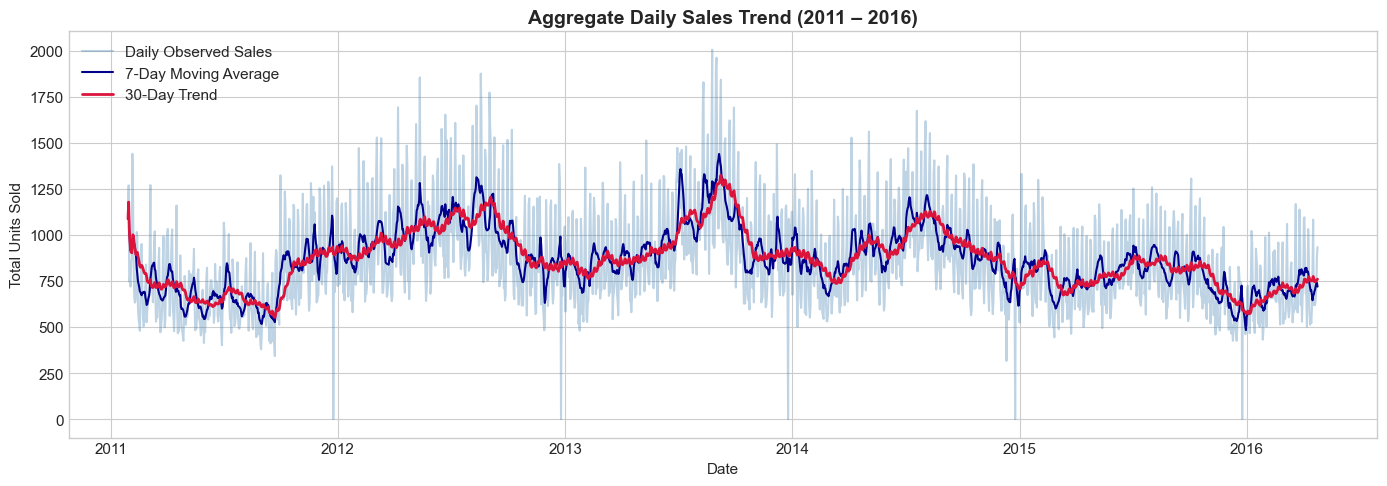

In [3]:
# Aggregating daily total sales across all monitored items.
daily_agg = df.groupby('date')['sales'].sum().reset_index()

# Calculating 7-day and 30-day rolling averages for trend smoothing.
daily_agg['rolling_7'] = daily_agg['sales'].rolling(window=7, min_periods=1).mean()
daily_agg['rolling_30'] = daily_agg['sales'].rolling(window=30, min_periods=1).mean()

# Visualizing aggregate historical demand with rolling smoothers.
plt.figure(figsize=(14, 5))
plt.plot(daily_agg['date'], daily_agg['sales'], alpha=0.35, color='steelblue', label='Daily Observed Sales')
plt.plot(daily_agg['date'], daily_agg['rolling_7'], color='darkblue', linewidth=1.5, label='7-Day Moving Average')
plt.plot(daily_agg['date'], daily_agg['rolling_30'], color='crimson', linewidth=2.0, label='30-Day Trend')
plt.title('Aggregate Daily Sales Trend (2011 – 2016)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig(figures_dir / '01_aggregate_sales_trend.png', dpi=200)
plt.show()

## 4. Seasonality Decomposition: Day-of-Week & Monthly Patterns

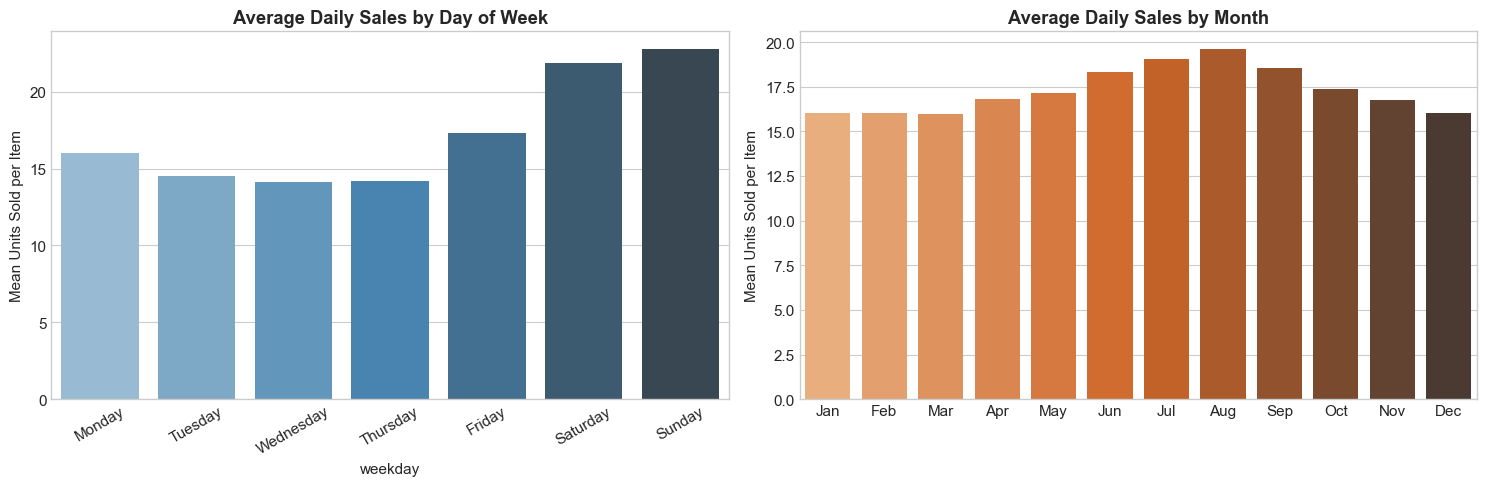

In [4]:
# Analyzing day-of-week sales volume distribution.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grouping by weekday name in chronological weekly sequence.
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_means = df.groupby('weekday')['sales'].mean().reindex(weekday_order)

sns.barplot(x=weekday_means.index, y=weekday_means.values, ax=axes[0], hue=weekday_means.index, palette='Blues_d', legend=False)
axes[0].set_title('Average Daily Sales by Day of Week', fontweight='bold')
axes[0].set_ylabel('Mean Units Sold per Item')
axes[0].set_xticks(range(len(weekday_order)))
axes[0].set_xticklabels(weekday_order, rotation=30)

# Analyzing monthly seasonality pattern.
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_means = df.groupby('month')['sales'].mean().reindex(range(1, 13))

sns.barplot(x=month_names, y=monthly_means.values, ax=axes[1], hue=month_names, palette='Oranges_d', legend=False)
axes[1].set_title('Average Daily Sales by Month', fontweight='bold')
axes[1].set_ylabel('Mean Units Sold per Item')

plt.tight_layout()
plt.savefig(figures_dir / '01_seasonality_patterns.png', dpi=200)
plt.show()

## 5. Intermittent Demand Analysis & Zero Inflation

Item Intermittency Statistics (Top 5):
       item_id  mean_sales  std_sales  zero_ratio  stockout_ratio  \
0  FOODS_1_085   10.641924   6.947792    0.018819        0.018819   
1  FOODS_1_218   11.702561   9.325353    0.053842        0.053842   
2  FOODS_2_019   18.465238  10.984678    0.084684        0.084684   
3  FOODS_2_197   21.274438  12.736485    0.083116        0.083116   
4  FOODS_2_244   10.476215   6.920014    0.074752        0.074752   

   active_days       cv2  
0         1913  0.426239  
1         1913  0.634993  
2         1913  0.353887  
3         1913  0.358412  
4         1913  0.436320  


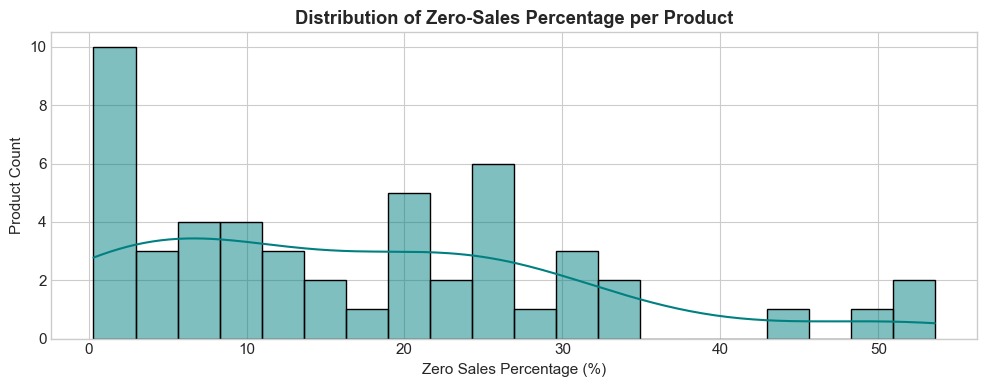

In [5]:
# Computing item-level demand intermittency metrics.
item_stats = df.groupby('item_id').agg(
    mean_sales=('sales', 'mean'),
    std_sales=('sales', 'std'),
    zero_ratio=('sales', lambda x: (x == 0).mean()),
    stockout_ratio=('potential_stockout', 'mean'),
    active_days=('is_active', 'sum')
).reset_index()

# Calculating squared coefficient of variation (CV^2) to classify demand patterns.
item_stats['cv2'] = (item_stats['std_sales'] / item_stats['mean_sales']) ** 2

print("Item Intermittency Statistics (Top 5):")
print(item_stats.head())

# Visualizing distribution of zero-sales proportion across items.
plt.figure(figsize=(10, 4))
sns.histplot(item_stats['zero_ratio'] * 100, bins=20, kde=True, color='teal')
plt.title('Distribution of Zero-Sales Percentage per Product', fontweight='bold')
plt.xlabel('Zero Sales Percentage (%)')
plt.ylabel('Product Count')
plt.tight_layout()
plt.savefig(figures_dir / '01_zero_sales_distribution.png', dpi=200)
plt.show()

## 6. Calendar Event & SNAP Benefit Lift Analysis

SNAP Benefit Impact on Daily Sales:
           Day Type       mean        std  count
0       Regular Day  16.731910  18.920908  64150
1  SNAP Benefit Day  18.351651  19.668917  31500


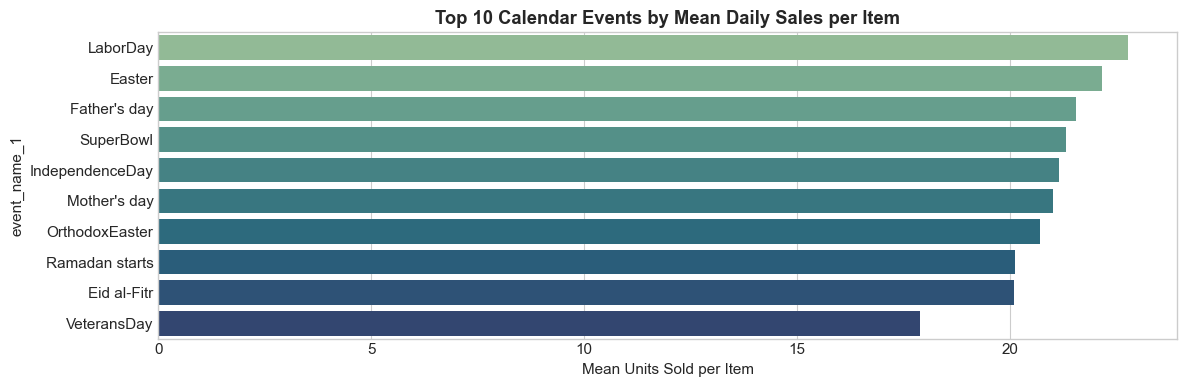

In [6]:
# Comparing sales on SNAP vs Non-SNAP days for store CA_1.
snap_comparison = df.groupby('snap_CA')['sales'].agg(['mean', 'std', 'count']).reset_index()
snap_comparison['Day Type'] = snap_comparison['snap_CA'].map({0: 'Regular Day', 1: 'SNAP Benefit Day'})

print("SNAP Benefit Impact on Daily Sales:")
print(snap_comparison[['Day Type', 'mean', 'std', 'count']])

# Analyzing top calendar events by average daily sales volume.
event_sales = df[df['event_name_1'].notna()].groupby('event_name_1')['sales'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 4))
sns.barplot(x=event_sales.values, y=event_sales.index, hue=event_sales.index, palette='crest', legend=False)
plt.title('Top 10 Calendar Events by Mean Daily Sales per Item', fontweight='bold')
plt.xlabel('Mean Units Sold per Item')
plt.tight_layout()
plt.savefig(figures_dir / '01_event_impact.png', dpi=200)
plt.show()

## 7. Pricing Distribution and Price Elasticity Overview

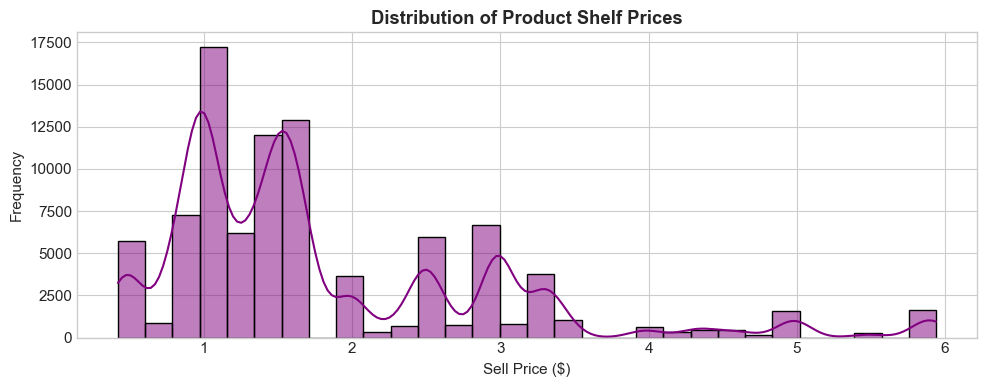

In [7]:
# Plotting selling price distribution for monitored products.
plt.figure(figsize=(10, 4))
sns.histplot(df['sell_price'].dropna(), bins=30, kde=True, color='purple')
plt.title('Distribution of Product Shelf Prices', fontweight='bold')
plt.xlabel('Sell Price ($)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(figures_dir / '01_price_distribution.png', dpi=200)
plt.show()

## 8. Summary of Exploratory Findings for Modeling
1. **Strong Weekend Seasonality**: Friday through Sunday account for the majority of weekly sales volume. Weekday lag features ($t-7, t-14$) will be highly predictive.
2. **Holiday Spikes & Closures**: Major sporting and cultural events stimulate noticeable demand spikes, while Christmas Day exhibits absolute closures with zero sales.
3. **Intermittent Demand & Zero Inflation**: A non-trivial proportion of active records contain zero sales. Traditional metrics like MAPE will divide by zero and become unstable; **WAPE** and **MAE** must be prioritized.
4. **Stockout Risk**: Distinguishing zero sales during active periods from structural unlisted periods is essential to prevent systematic under-forecasting.